In [1]:
import tqdm
import torch
import numpy as np
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
import tokenizers


In [2]:
print("Loading dataset...")

# Load dataset from JSON file
dataset = load_dataset('json', data_files='data/chat_data_simple.json', split='train')

print(len(dataset))
# print(json.dumps(dataset[0], indent=2))
print(dataset[0].keys())
print(dataset[0]['messages'][0]['content'])


Loading dataset...
3
dict_keys(['messages'])
what is your name


### initial device

In [3]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

print(f"using device : {device}")


using device : cpu


### load qwen model and tokenizer

In [4]:
import os
save_path = "./model_cache/qwen2.5-0.5b"
model_name = "Qwen/Qwen2.5-0.5B"
if not os.path.exists(save_path):
    model = AutoModelForCausalLM.from_pretrained(model_name)
    tokenizer = AutoTokenizer.from_pretrained(model_name)
else:
    model = AutoModelForCausalLM.from_pretrained(save_path)
    tokenizer = AutoTokenizer.from_pretrained(save_path)    


### print dataset

In [17]:
for i in dataset:
    # Get the tokenizer's pad token id
    pad_token_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
    print(i['messages'])
    # Apply chat template with explicit padding
    input_ids = tokenizer.apply_chat_template(
        i['messages'],
        return_tensors="pt",
        padding='max_length',  # Changed to 'max_length'
        max_length=64,
        truncation=True,
    ).to(device)
    
    # Ensure the sequence is exactly 64 tokens
    if input_ids.shape[1] < 64:
        padding_needed = 64 - input_ids.shape[1]
        padding = torch.full((1, padding_needed), pad_token_id, device=device)
        input_ids = torch.cat([input_ids, padding], dim=1)
    
    # Create attention mask
    attention_mask = (input_ids != pad_token_id).long()
    
    print(f"\nInput shape: {input_ids.shape}")
    print("\nDecoded text:")
    print(tokenizer.decode(input_ids[0]))
    print("\nAttention mask (should see 0s for padding):")
    print(attention_mask[0].tolist())
    print(f"\nNumber of actual tokens: {attention_mask.sum().item()}")
    print(f"Total length: {len(attention_mask[0])}")
    
    break

[{'content': 'what is your name', 'role': 'user'}, {'content': 'Julie', 'role': 'assistant'}]

Input shape: torch.Size([1, 64])

Decoded text:
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
what is your name<|im_end|>
<|im_start|>assistant
Julie<|im_end|>
<|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|>

Attention mask (should see 0s for padding):
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [18]:
# First, create the data processing function
def prepare_training_data(dataset):
    input_ids = []
    attention_masks = []
    for item in dataset:
        # Format each conversation
        messages = item['messages']
        input_id = tokenizer.apply_chat_template(messages,
                                                     tokenize=True,
                                                     return_tensors="pt",
                                                     padding='max_length',  # Changed to 'max_length'
                                                     max_length=64,
                                                     truncation=True,
                                                     continue_final_message=False
                                                     )

        
        input_ids.append(input_id)
        # Ensure the sequence is exactly 64 tokens
        if input_id.shape[1] < 64:
            padding_needed = 64 - input_id.shape[1]
            padding = torch.full((1, padding_needed), pad_token_id, device=device)
            input_id = torch.cat([input_id, padding], dim=1)
            
        # Create attention mask
        attention_mask = (input_id != pad_token_id).long()
        attention_masks.append(attention_mask)
    
    # Create dataset
    class ChatDataset(torch.utils.data.Dataset):
        def __init__(self, input_ids, attention_masks):
            self.input_ids = input_ids
            self.attention_masks = attention_masks
            
        def __len__(self):
            return len(self.input_ids)
            
        def __getitem__(self, idx):
            return self.input_ids[idx], self.attention_mask[idx]
    
    return ChatDataset(input_ids, attention_masks)

# Now modify your training setup code
# Create the processed dataset and dataloader
processed_dataset = prepare_training_data(dataset)
train_dataloader = torch.utils.data.DataLoader(
    processed_dataset,
    batch_size=4,
    shuffle=True
)


<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
what is your name<|im_end|>
<|im_start|>assistant
Julie<|im_end|>

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
what is your hobbes<|im_end|>
<|im_start|>assistant
I love painting, i love to paint<|im_end|>

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
do you have a girlfriend<|im_end|>
<|im_start|>assistant
no, I have a boyfriend<|im_end|>



In [7]:
for i, a in train_dataloader:
    input_ids = i
    attention_mask = a
    print(input_ids.shape)
    print(attention_mask.shape)
    print(input_ids[0])
    print(tokenizer.batch_decode(input_ids[0], skip_special_tokens=False))
    print(attention_mask[0])
    print('-'*50)
    break


torch.Size([3, 34])
torch.Size([3, 34])
tensor([151644,   8948,    198,   2610,    525,    264,  10950,  17847,     13,
        151645,    198, 151644,    872,    198,  12555,    374,    697,    829,
        151645,    198, 151644,  77091,    198,  28085,    645, 151645,    198,
        151643, 151643, 151643, 151643, 151643, 151643, 151643])
['<|im_start|>', 'system', '\n', 'You', ' are', ' a', ' helpful', ' assistant', '.', '<|im_end|>', '\n', '<|im_start|>', 'user', '\n', 'what', ' is', ' your', ' name', '<|im_end|>', '\n', '<|im_start|>', 'assistant', '\n', 'Jul', 'ie', '<|im_end|>', '\n', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>']
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 0, 0, 0, 0, 0, 0, 0])
--------------------------------------------------


In [8]:
tokenizer.convert_ids_to_tokens(33975)

'Human'

### test qwen model

In [10]:
print("test qwen model : ")
input_tokens = tokenizer.encode("what is your name", return_tensors="pt").to(device)
output_ids = model.generate(input_tokens, 
                            max_length=50, 
                            pad_token_id=tokenizer.pad_token_id, 
                            eos_token_id=tokenizer.eos_token_id, 
                            temperature=0.9)
print(tokenizer.batch_decode(output_ids, skip_special_tokens=True))


Both `max_new_tokens` (=2048) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


test qwen model : 
['what is your name?\nI am a computer program designed to assist with various tasks and provide information. My name is not explicitly stated in the text you provided, but I can provide some general information about me. As an AI language model, I am designed to understand and respond to user queries, provide information, and assist with tasks. My name is not a specific name, but rather a placeholder for the name of the program.']


### define generate answer function

In [14]:
def infer(inp, model):
    # Format the input with Qwen chat template
    formatted_prompt = f"""<|im_start|>system
        You are a helpful assistant.<|im_end|>
        <|im_start|>user
        {inp}<|im_end|>
        <|im_start|>assistant"""
    inp = tokenizer(formatted_prompt, return_tensors="pt").to(device)
    
    # Add debugging prints
    # print(f"Input device: {inp.input_ids.device}")
    # print(f"Model device: {next(model.parameters()).device}")
    
    output = model.generate(
        **inp,
        min_length=20,
        max_length=100,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
        do_sample=True,
        temperature=0.9,
        top_p=0.9,
        top_k=50,
        no_repeat_ngram_size=2,
        num_return_sequences=1,
        early_stopping=True
    )
    
    # Add debugging print
    # print(f"Raw output: {output}")
    
    output = tokenizer.batch_decode(output[0], skip_special_tokens=False)
    # print(f"inferoutput : {output}")
    return output

### define train function

In [15]:
def train(dataLoader, model):

    epochs = 12
    losses = []  # Add list to store losses
    print_count = 0
    max_prints = 1
    print_shape = True
    
    for i in tqdm.tqdm(range(epochs)):
        epoch_losses = []  # Store losses for each epoch
        print(f"\n\n epoch {i} started")
        for X, a in dataLoader:
            X = X.to(device)
            a = a.to(device)
            # optim.zero_grad()
            loss = model(X, attention_mask=a, labels=X).loss
            loss.backward()
            # optim.step()
            
            epoch_losses.append(loss.item())  # Store the loss value
            
            if print_shape:
                print(f"X shape: {X.shape}, a shape: {a.shape}")

            # print(f"Loss: {loss.item():.4f}")

            # print("\nComparing full text vs active tokens:")
            if print_shape:
                # Decode full text for first example
                full_text = tokenizer.decode(X[0], skip_special_tokens=False)
                print("Full text:", full_text)
                
                # Get and decode active tokens for first example
                active_positions = a[0].nonzero().squeeze()
                active_tokens = X[0][active_positions]
                decoded_active = tokenizer.decode(active_tokens, skip_special_tokens=False)
                print("Active tokens:", decoded_active)
                print("-" * 50)
                print_shape = False
        
        # Calculate and store average loss for the epoch
        avg_epoch_loss = sum(epoch_losses) / len(epoch_losses)
        losses.append(avg_epoch_loss)
        
        # Save losses to file after each epoch
        if not os.path.exists('losses'):
            os.makedirs('losses')
        np.savetxt('losses/training_losses.txt', losses)
        
        print(f"Average loss for epoch {i}: {avg_epoch_loss:.4f}")
        torch.save(model.state_dict(), "finetuned_model/model_state.pt")
        print(f"epoch {i} completed")
        model.eval()
        print(infer("what is your name", model))
        model.train()


### train model

In [16]:
# set model to train mode
model.train()

# optimizer
# optim = Adam(model.parameters(), lr=1e-3)

# train model
print("training .... ")
train(train_dataloader, model)

training .... 


  0%|          | 0/12 [00:00<?, ?it/s]



 epoch 0 started
X shape: torch.Size([3, 34]), a shape: torch.Size([3, 34])
Full text: <|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
what is your name<|im_end|>
<|im_start|>assistant
Julie<|im_end|>
<|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|>
Active tokens: <|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
what is your name<|im_end|>
<|im_start|>assistant
Julie<|im_end|>

--------------------------------------------------
Average loss for epoch 0: 7.8977


C:\Users\86137\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\transformers\generation\configuration_utils.py:676: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `early_stopping`.
  warnings.warn(
Both `max_new_tokens` (=2048) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


epoch 0 completed


...

Raw output: tensor([[151644,   8948,    198,    286,   1446,    525,    264,  10950,  17847,
             13, 151645,    198,    260, 151644,    872,    198,    286,   1128,
            374,    697,    829, 151645,    198,    260, 151644,  77091,    198,
          15677,    286,    358,   1079,  14589,    714,    358,    653,    537,
            614,   2615,    311,    279,   1849,    829,    624,  57661,     17,
             16,     24,     18,   8948,   8948,    220,   1446,   2299,   5008,
           1290,     13,   1634,    458,  15235,   1849,     11,    847,   6540,
            374,   3118,    389,    279,   1429,   1482,   1995,   2500,    311,
            752,     11,    323,    358,   4157,   3410,    498,    448,    279,
           1482,   1849,    594,    829,    382,  57661,     18,     16,     15,
             22,   8948,  43111,    220,   2585,    653,    498,   1414,    429,
            498,   2299,    264,   6366,   5267,  57661,     19,     16,     17,
             22,

Both `max_new_tokens` (=2048) and `max_length`(=100) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


epoch 5 completed


 42%|████▏     | 5/12 [04:07<05:46, 49.54s/it]


KeyboardInterrupt: 

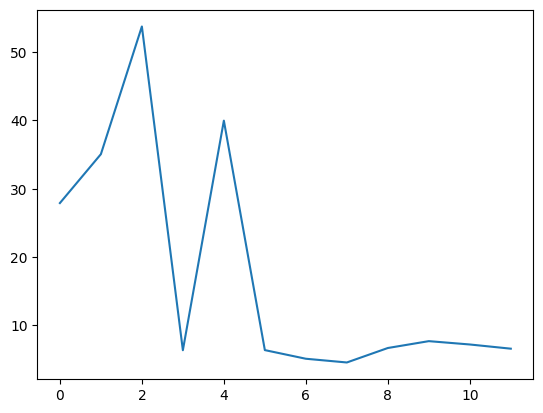

In [23]:
# draw matplotlib
import matplotlib.pyplot as plt
losses = np.loadtxt('losses/training_losses.txt')
plt.plot(losses)
plt.show()


### test SFT model

In [24]:

inp = "who are you  "
response = infer(inp, model)
print("Bot:", response)

Input device: cpu
Model device: cpu


/home/ying/.local/lib/python3.8/site-packages/transformers/generation/configuration_utils.py:615: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `early_stopping`.
  warnings.warn(


Raw output: tensor([[50258,   508,   389,   345,   220,   220,   220, 50260,   220, 50257,
         50257, 50258, 50257, 50260, 50257,   220, 50258, 50260, 50260, 50258,
         50259]])
Bot:  who are you    <bot>:   <bot>:   <bot>: <bot>:


### load SFT model and test

In [25]:
# Load model and resize token embeddings
model_finetuned = GPT2LMHeadModel.from_pretrained("gpt2")
model_finetuned.resize_token_embeddings(len(tokenizer))

# Load the saved state
model_finetuned.load_state_dict(torch.load("model_state.pt"))
model_finetuned = model_finetuned.to(device)
model_finetuned.eval()  # Set to evaluation mode


/tmp/ipykernel_3518927/1747311727.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_finetuned.load_state_dict(torch.load("model_state.pt"))


GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50261, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2SdpaAttention(
          (c_attn): Conv1D()
          (c_proj): Conv1D()
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D()
          (c_proj): Conv1D()
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50261, bias=False)
)

In [26]:
inp = "who are you  "
response = infer(inp, model_finetuned)
print("Bot:", response)

Input device: cpu
Model device: cpu
Raw output: tensor([[50258,   508,   389,   345,   220,   220,   220, 50260,   220, 50257,
         50257, 50260, 50257, 50258, 50257,   393, 50257,   284, 50257,   220,
         50259]])
Bot:  who are you    <bot>:   <bot>:  or to 
